In [36]:
# ============================================
# STEP 1: COLLECT + EXTRACT ORLANDO SOURCES
# ============================================

import requests
import pandas as pd
import fitz
from bs4 import BeautifulSoup
from urllib.parse import urljoin, urlparse
import time


# -----------------------------
# 1. Load UScityURL and get Orlando
# -----------------------------

city_data_url = "https://raw.githubusercontent.com/caimeng2/UScityURL/master/UScityURL.csv"

cities = pd.read_csv(city_data_url)

orlando = cities[
    (cities["MUNICIPALITY"].str.lower() == "orlando") &
    (cities["STATE"].str.lower() == "florida")
]

base_url = orlando.iloc[0]["WEBSITE_URL"]

print("Orlando website:", base_url)


# -----------------------------
# 2. Define resilience-related keywords
# -----------------------------

keywords = [
    "resilience",
    "resiliency",
    "hazard",
    "mitigation",
    "climate",
    "adaptation",
    "emergency",
    "flood",
    "hurricane",
    "storm",
    "sustainability",
    "future ready",
    "comprehensive plan",
    "master plan"
]


# -----------------------------
# 3. Function to request a webpage
# -----------------------------

headers = {
    "User-Agent": "Mozilla/5.0"
}

def get_page(url):
    try:
        r = requests.get(
            url,
            headers=headers,
            timeout=15
        )
        return r
    except:
        return None


# -----------------------------
# 4. Function to collect links from one page
# -----------------------------

def get_links(url):

    response = get_page(url)

    if response is None:
        return []

    soup = BeautifulSoup(
        response.text,
        "html.parser"
    )

    links = []

    for a in soup.find_all("a", href=True):

        full_url = urljoin(
            url,
            a["href"]
        )

        anchor_text = a.get_text(
            " ",
            strip=True
        )

        links.append({
            "anchor_text": anchor_text,
            "url": full_url
        })

    return links


# -----------------------------
# 5. Crawl a small sample of Orlando.gov
# -----------------------------

to_visit = [base_url]

visited = set()

all_links = []

max_pages = 200


while to_visit and len(visited) < max_pages:

    current_url = to_visit.pop(0)

    if current_url in visited:
        continue

    print("Visiting:", current_url)

    visited.add(current_url)

    links = get_links(current_url)

    all_links.extend(links)

    for item in links:

        link = item["url"]

        # Only stay on Orlando.gov
        if "orlando.gov" in urlparse(link).netloc:

            # Ignore image/archive files
            if not link.lower().endswith(
                (".jpg", ".jpeg", ".png", ".zip")
            ):

                if link not in visited:
                    to_visit.append(link)

    time.sleep(0.2)


# -----------------------------
# 6. Turn collected links into dataframe
# -----------------------------

links_df = pd.DataFrame(all_links)

# Remove duplicate URLs
links_df = links_df.drop_duplicates(
    subset="url"
).copy()

print("Total unique links found:", len(links_df))


# -----------------------------
# 7. Find resilience-related links
# -----------------------------

links_df["search_text"] = (
    links_df["anchor_text"].fillna("") +
    " " +
    links_df["url"].fillna("")
).str.lower()


def find_keywords(text):

    found = []

    for word in keywords:

        if word in text:
            found.append(word)

    return found


links_df["keywords_found"] = (
    links_df["search_text"]
    .apply(find_keywords)
)


relevant_links = links_df[
    links_df["keywords_found"].str.len() > 0
].copy()

print("Relevant links found:", len(relevant_links))


# -----------------------------
# 8. Create documents dataframe
# -----------------------------
# We keep only first 30 for this pilot.

documents = relevant_links.head(30).copy()


# -----------------------------
# 9. NOW create the type column
# -----------------------------

documents["type"] = documents["url"].apply(
    lambda url: "PDF"
    if ".pdf" in str(url).lower()
    else "HTML"
)


# -----------------------------
# 10. Extract text from HTML
# -----------------------------

def extract_html(url):

    response = get_page(url)

    if response is None:
        return ""

    soup = BeautifulSoup(
        response.text,
        "html.parser"
    )

    # Remove common website boilerplate
    for tag in soup([
        "script",
        "style",
        "nav",
        "footer",
        "header"
    ]):
        tag.decompose()

    return soup.get_text(
        " ",
        strip=True
    )


# -----------------------------
# 11. Extract text from PDF
# -----------------------------

def extract_pdf(url):

    response = get_page(url)

    if response is None:
        return ""

    try:

        pdf = fitz.open(
            stream=response.content,
            filetype="pdf"
        )

        text = ""

        for page in pdf:
            text += page.get_text()

        return text

    except:
        return ""


# -----------------------------
# 12. Choose extraction method automatically
# -----------------------------

def extract_text(row):

    if row["type"] == "PDF":
        return extract_pdf(row["url"])

    else:
        return extract_html(row["url"])


# -----------------------------
# 13. Extract the text
# -----------------------------

documents["raw_text"] = documents.apply(
    extract_text,
    axis=1
)


# -----------------------------
# 14. Measure how much text was extracted
# -----------------------------

documents["raw_length"] = (
    documents["raw_text"]
    .fillna("")
    .str.len()
)


# -----------------------------
# 15. Check the columns
# -----------------------------

print("\nColumns:")
print(documents.columns.tolist())


# -----------------------------
# 16. View results
# -----------------------------

display(
    documents[
        [
            "anchor_text",
            "url",
            "type",
            "raw_length",
            "keywords_found"
        ]
    ].head(20)
)

Orlando website: https://www.orlando.gov/
Visiting: https://www.orlando.gov/
Visiting: https://www.orlando.gov/#main-content
Visiting: https://www.orlando.gov/Home?oc_lang=en-US
Visiting: https://www.orlando.gov/Home?oc_lang=es
Visiting: https://www.orlando.gov/Home?oc_lang=ht
Visiting: https://www.orlando.gov/Home?oc_lang=pt
Visiting: https://www.orlando.gov/Home
Visiting: https://www.orlando.gov/Report-a-Problem
Visiting: https://www.orlando.gov/Report-a-Problem/Report-a-Crime
Visiting: https://www.orlando.gov/Report-a-Problem/Report-a-Code-Enforcement-Violation
Visiting: https://www.orlando.gov/Report-a-Problem/Report-a-Transportation-Problem
Visiting: https://www.orlando.gov/Report-a-Problem/Report-a-Transportation-Problem/Report-a-Pothole
Visiting: https://www.orlando.gov/Report-a-Problem/Report-a-Transportation-Problem/Report-a-Broken-Sidewalk
Visiting: https://www.orlando.gov/Report-a-Problem/Report-a-Transportation-Problem/Report-a-Traffic-Signal-Issue
Visiting: https://www.orl

,anchor_text,url,type,raw_length,keywords_found
26,Report Flooding,https://www.orlando.gov/Report-a-Problem/Repor...,HTML,1683,[flood]
29,Report Lake or Stormwater Pollution,https://www.orlando.gov/Report-a-Problem/Repor...,HTML,2586,[storm]
55,The Emergency Operations Center Building Expan...,https://www.orlando.gov/Building-Development/C...,HTML,1273,[emergency]
74,Floodplain Management Plan Study,https://www.orlando.gov/Building-Development/C...,HTML,4296,[flood]
105,Community Development Block Grants & Emergency...,https://www.orlando.gov/Building-Development/H...,HTML,5773,[emergency]
110,AIPO T50/T51 Four Industrial Warehouses Master...,https://www.orlando.gov/Building-Development/M...,HTML,2144,[master plan]
207,Report Storm Debris,https://www.orlando.gov/Trash-Recycling/Report...,HTML,4453,[storm]
340,Find out if you live in a Floodplain,https://www.orlando.gov/Parks-the-Environment/...,HTML,3725,[flood]
366,Become a Police Department Emergency Communica...,https://www.orlando.gov/Public-Safety/OPD/Beco...,HTML,5195,[emergency]
390,Submit Emergency Radio Signal Surveys,https://www.orlando.gov/Public-Safety/OFD/Subm...,HTML,697,[emergency]


In [37]:
# Check all discovered links for PDFs

pdf_links = links_df[
    links_df["url"].str.lower().str.contains(".pdf", na=False)
]

print("Total PDF links discovered:", len(pdf_links))

display(
    pdf_links[
        ["anchor_text", "url"]
    ].head(20)
)

Total PDF links discovered: 41


,anchor_text,url
23181,narrative,https://www.orlando.gov/files/sharedassets/pub...
32341,Download the Presentation from the Community M...,https://www.orlando.gov/files/sharedassets/pub...
32978,"Download the study area map (PDF, 681KB)",https://www.orlando.gov/files/sharedassets/pub...
32979,Download the Bike and Pedestrian Safety Recomm...,https://www.orlando.gov/files/sharedassets/pub...
32980,Download the Bike and Pedestrian Study Summary...,https://www.orlando.gov/files/sharedassets/pub...
32981,Download the Off Streets Trails Concepts and O...,https://www.orlando.gov/files/sharedassets/pub...
32982,Download the Pedestrian Walking Conditions Tec...,https://www.orlando.gov/files/sharedassets/pub...
32983,Download the Valencia College West Campus Tech...,https://www.orlando.gov/files/sharedassets/pub...
37463,"Download the roundabout board (, 0B)",https://www.orlando.gov/files/sharedassets/pub...
37464,"VZ Progress Report (PDF, 4MB)",https://www.orlando.gov/files/sharedassets/pub...


In [38]:
# ============================================
# STEP 2: CLEAN + ORGANIZE THE DATA
# ============================================

# -----------------------------
# 1. Clean extracted text
# -----------------------------
# We only do light cleaning:
# - remove extra spaces
# - remove tabs/newlines
# - keep punctuation and original wording

def clean_text(text):

    if not isinstance(text, str):
        return ""

    # Replace repeated spaces, tabs, and newlines with one space
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


documents["clean_text"] = (
    documents["raw_text"]
    .apply(clean_text)
)


# -----------------------------
# 2. Measure cleaned text length
# -----------------------------

documents["clean_length"] = (
    documents["clean_text"]
    .str.len()
)


# -----------------------------
# 3. Create short titles for plots
# -----------------------------
# Some Orlando anchor text is very long.
# We keep the original anchor_text,
# but make a shorter version only for plotting.

def short_title(text):

    text = str(text).strip()

    if len(text) > 55:
        return text[:55] + "..."

    return text


documents["display_title"] = (
    documents["anchor_text"]
    .apply(short_title)
)


# -----------------------------
# 4. Detect exact duplicate text
# -----------------------------

documents["duplicate"] = (
    documents["clean_text"]
    .duplicated(
        keep=False
    )
)


# -----------------------------
# 5. Create extraction quality labels
# -----------------------------
# These are simple rules for the pilot.

def extraction_quality(length):

    if length == 0:
        return "Failed"

    elif length < 500:
        return "Very Low"

    elif length < 2000:
        return "Low"

    elif length < 4000:
        return "Medium"

    else:
        return "High"


documents["quality"] = (
    documents["clean_length"]
    .apply(extraction_quality)
)


# -----------------------------
# 6. Add city metadata
# -----------------------------

documents["city"] = "Orlando"
documents["state"] = "Florida"


# -----------------------------
# 7. Create final clean dataframe
# -----------------------------

clean_df = documents[
    [
        "city",
        "state",
        "anchor_text",
        "display_title",
        "url",
        "type",
        "keywords_found",
        "raw_length",
        "clean_length",
        "quality",
        "duplicate",
        "clean_text"
    ]
].copy()


# -----------------------------
# 8. View cleaned dataset
# -----------------------------

display(
    clean_df[
        [
            "display_title",
            "type",
            "raw_length",
            "clean_length",
            "quality",
            "duplicate"
        ]
    ].head(20)
)


# -----------------------------
# 9. Save cleaned data
# -----------------------------

clean_df.to_csv(
    "orlando_resilience_documents.csv",
    index=False
)

print("Saved: orlando_resilience_documents.csv")

,display_title,type,raw_length,clean_length,quality,duplicate
26,Report Flooding,HTML,1683,1682,Low,True
29,Report Lake or Stormwater Pollution,HTML,2586,2585,Medium,True
55,The Emergency Operations Center Building Expan...,HTML,1273,1250,Low,False
74,Floodplain Management Plan Study,HTML,4296,4273,High,False
105,Community Development Block Grants & Emergency...,HTML,5773,5772,High,False
110,AIPO T50/T51 Four Industrial Warehouses Master...,HTML,2144,2120,Medium,False
207,Report Storm Debris,HTML,4453,4452,High,False
340,Find out if you live in a Floodplain,HTML,3725,3724,Medium,False
366,Become a Police Department Emergency Communica...,HTML,5195,5194,High,False
390,Submit Emergency Radio Signal Surveys,HTML,697,696,Low,False


Saved: orlando_resilience_documents.csv


Total documents: 30

Document types:
type
HTML    30
Name: count, dtype: int64

Extraction quality:
quality
Low         9
Medium      8
High        6
Very Low    6
Failed      1
Name: count, dtype: int64


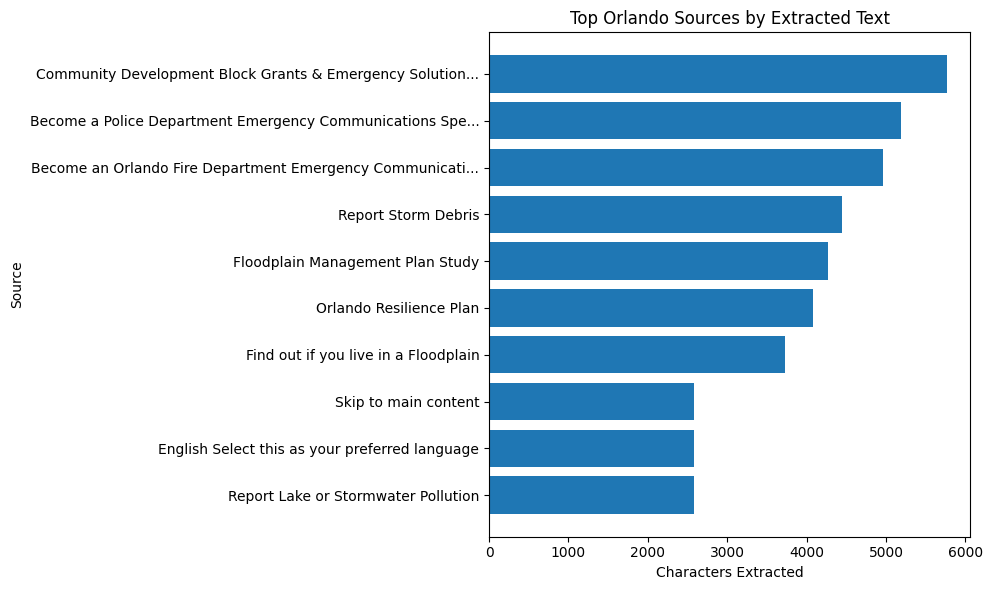

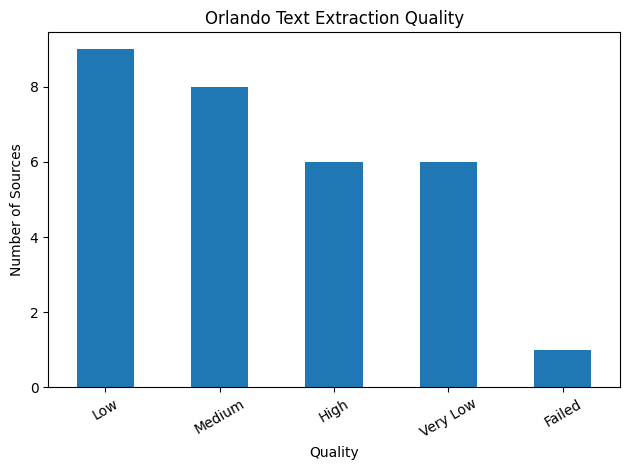

,topic,count
2,flood,122
4,storm,102
8,emergency,47
6,housing,29
0,resilience,22
3,hurricane,7
9,mitigation,5
5,heat,4
7,infrastructure,4
1,climate,2


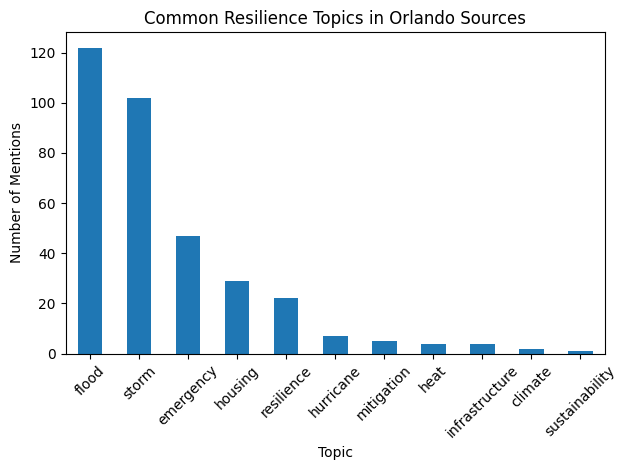

,word,count
0,report,119
1,step,98
2,flooding,74
3,stormwater,54
4,fire,54
5,department,53
6,storm,48
7,emergency,47
8,request,43
9,service,41


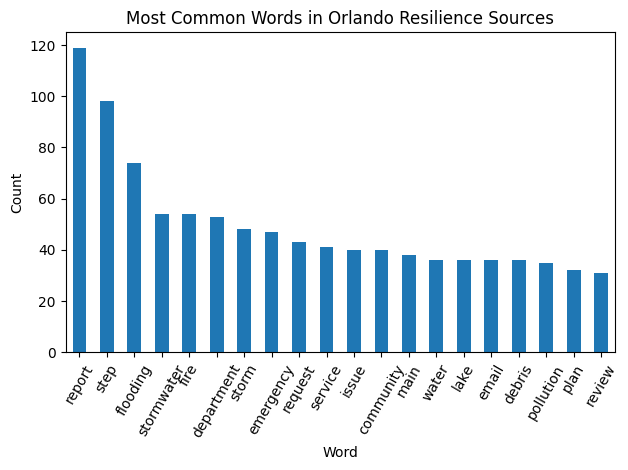

Extraction success rate: 96.7 %


,display_title,url,type,clean_length,quality
436,"Volunteer with the Office of Sustainability, R...",https://www.orlando.gov/Community-Programs-Eve...,HTML,13,Very Low
7681,View Map,https://maps.google.com?q=Streets%20and%20Stor...,HTML,131,Very Low
14159,Report Flooding,https://us.openforms.com/Form/d2f15c6a-b6ba-45...,HTML,105,Very Low
14160,View Map,https://maps.google.com?q=Streets%20and%20Stor...,HTML,131,Very Low
14171,Facebook,https://www.facebook.com/sharer/sharer.php?u=h...,HTML,97,Very Low
14172,X,https://twitter.com/share?url=https%3a%2f%2fww...,HTML,493,Very Low
14173,Email,mailto:?Body=https%3a%2f%2fwww.orlando.gov%2fR...,HTML,0,Failed


In [39]:
# ============================================
# STEP 3: EXPLORATORY DATA ANALYSIS
# ============================================

import matplotlib.pyplot as plt
from collections import Counter


# -----------------------------
# 1. Number of documents
# -----------------------------

print("Total documents:", len(clean_df))

print("\nDocument types:")
print(clean_df["type"].value_counts())

print("\nExtraction quality:")
print(clean_df["quality"].value_counts())


# -----------------------------
# 3. Plot top documents by extracted text
# -----------------------------

plot_df = (
    clean_df
    .sort_values(
        "clean_length",
        ascending=False
    )
    .head(10)
    .sort_values(
        "clean_length"
    )
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["display_title"],
    plot_df["clean_length"]
)

plt.title("Top Orlando Sources by Extracted Text")
plt.xlabel("Characters Extracted")
plt.ylabel("Source")

plt.tight_layout()
plt.show()


# -----------------------------
# 4. Plot extraction quality
# -----------------------------

clean_df["quality"].value_counts().plot(
    kind="bar"
)

plt.title("Orlando Text Extraction Quality")
plt.xlabel("Quality")
plt.ylabel("Number of Sources")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# -----------------------------
# 5. Define resilience topics
# -----------------------------

topics = [
    "resilience",
    "climate",
    "flood",
    "hurricane",
    "storm",
    "heat",
    "housing",
    "infrastructure",
    "emergency",
    "mitigation",
    "sustainability"
]


# -----------------------------
# 6. Combine all cleaned text
# -----------------------------

all_text = " ".join(
    clean_df["clean_text"]
).lower()


# -----------------------------
# 7. Count resilience topics
# -----------------------------

topic_counts = {}

for topic in topics:

    topic_counts[topic] = (
        all_text.count(topic)
    )


topic_df = pd.DataFrame(
    topic_counts.items(),
    columns=[
        "topic",
        "count"
    ]
).sort_values(
    "count",
    ascending=False
)

display(topic_df)


# -----------------------------
# 8. Plot resilience topics
# -----------------------------

topic_df.plot(
    x="topic",
    y="count",
    kind="bar",
    legend=False
)

plt.title("Common Resilience Topics in Orlando Sources")
plt.xlabel("Topic")
plt.ylabel("Number of Mentions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# -----------------------------
# 9. Most common words
# -----------------------------

words = re.findall(
    r"\b[a-zA-Z]{4,}\b",
    all_text
)

# Small stopword list to remove common/unhelpful words
stop_words = {
    "that",
    "this",
    "with",
    "from",
    "will",
    "city",
    "orlando",
    "your",
    "have",
    "more",
    "their",
    "about",
    "which",
    "they",
    "page",
    "information"
}

words = [
    word
    for word in words
    if word not in stop_words
]

word_counts = Counter(words)

top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=[
        "word",
        "count"
    ]
)

display(top_words)


# -----------------------------
# 10. Plot most common words
# -----------------------------

top_words.plot(
    x="word",
    y="count",
    kind="bar",
    legend=False
)

plt.title("Most Common Words in Orlando Resilience Sources")
plt.xlabel("Word")
plt.ylabel("Count")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


# -----------------------------
# 11. Extraction success rate
# -----------------------------

successful = (
    clean_df["clean_length"] > 0
).sum()

total = len(clean_df)

success_rate = (
    successful / total
) * 100

print(
    "Extraction success rate:",
    round(success_rate, 1),
    "%"
)


# -----------------------------
# 12. Check possible problem pages
# -----------------------------
# These may be scanned PDFs, short pages,
# redirects, or pages with little usable text.

problem_pages = clean_df[
    clean_df["clean_length"] < 500
]

display(
    problem_pages[
        [
            "display_title",
            "url",
            "type",
            "clean_length",
            "quality"
        ]
    ]
)

## Top 5 Questions After the EDA

1. Which resilience topics are most and least represented across Orlando's municipal documents?

2. Which documents provide the broadest coverage of resilience issues, and which are narrowly focused on specific hazards?

3. Are important resilience topics spread across many different plans and departments, or concentrated in a small number of documents?

4. Which topics frequently appear together, such as flooding with infrastructure or climate with extreme heat?

5. Where does our collection or extraction pipeline appear incomplete, and what kinds of sources are being missed or poorly extracted?


## Top 5 Most Impactful Applications

1. **Municipal Resilience Profile**  
   Create a clear profile of Orlando showing which resilience topics are strongly, moderately, or weakly represented in the collected documents.

2. **Resilience Gap Identification**  
   Identify topics that receive limited coverage in the collected sources and flag them for further investigation.

3. **Cross-City Resilience Comparison**  
   Apply the same pipeline to other municipalities and compare their resilience priorities, document coverage, and planning approaches.

4. **Automated Resilience Document Discovery System**  
   Build a system that automatically finds, extracts, cleans, and organizes resilience-related municipal documents.

5. **National Municipal Resilience Dataset**  
   Scale the Orlando pilot into a standardized dataset that researchers and planners can use to study resilience planning across U.S. municipalities.